In [1]:
""" Kenya Food Market Prices Analysis in Python"""

import pandas as pd
import numpy as np
from pathlib import Path
from matplotlib import pyplot as plt


DATA_PATH = Path("data") / "food-prices-kenya.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94


In [2]:
# EDA

# df.sample(5)
# df.info()
df.isnull().sum()

date           0
region        59
county        59
market         0
commodity      0
price_type     0
unit           0
price_kes      0
price_usd      0
dtype: int64

In [3]:
""" Load and clean the prices
- Turn the date column into real dates, add year and month columns, and fill the missing county and region for the market that has none.
- How many rows, markets and commodities does the file have, and what are the first and last dates?
- Which market has no county, and how many rows does that affect?
"""

# Convert the date column into real datetime objects
df['date'] = pd.to_datetime(df['date'])

# Extract and add year and month columns
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

# Fill the missing county and region for Hola market
# Hola is located in Tana River county within the Coast region
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')




# Confirming the changes made to the date column
# df['date'].info()

# # confirming the changes made to the county and region columns
# df['county'].info()
# df['region'].info()
# df.sample(5)


# Highest and lowest date in the dataset
highest_date = df['date'].max()
lowest_date = df['date'].min()

print(highest_date)
print(lowest_date)



2019-12-15 00:00:00
2006-01-15 00:00:00


In [4]:
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])

df.sample(10)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
486,2017-01-15,Rift Valley,Kajiado,Kajiado,Maize,Retail,KG,48.00,0.46,2017,1,48.000000
1716,2013-03-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,5456.00,63.81,2013,3,60.622222
2145,2016-06-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2600.00,25.69,2016,6,28.888889
2270,2012-12-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,3200.00,37.19,2012,12,35.555556
2359,2006-08-15,Coast,Mombasa,Mombasa,Maize,Wholesale,90 KG,1131.25,15.58,2006,8,12.569444
1615,2018-07-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,6410.00,63.84,2018,7,71.222222
982,2011-08-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,63.00,0.68,2011,8,63.000000
2599,2012-12-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,2993.00,34.78,2012,12,33.255556
989,2012-03-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,78.00,0.95,2012,3,78.000000
161,2009-08-15,Eastern,Kitui,Kitui,Beans,Retail,KG,60.00,0.79,2009,8,60.000000


In [5]:
""" Compare like with like
Split the data into wholesale (per 90 KG bag) and retail (per KG) prices and never average them together. 
Add a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.
- Which units appear for wholesale maize and for retail maize?
- On average, how does the retail price per KG of maize compare with the wholesale price per KG?
"""

# Compare wholesale and retail maize prices only
maize = df[df["commodity"] == "Maize"]

# Units used for each maize price type
print(maize.groupby("price_type")["unit"].unique())

# Average price per kilogram by price type
average_prices = maize.groupby("price_type")["price_per_kg"].mean()
print(average_prices)

retail_average = average_prices["Retail"]
wholesale_average = average_prices["Wholesale"]

print(f"Average retail price per KG: KES {retail_average:.2f}")
print(f"Average wholesale price per KG: KES {wholesale_average:.2f}")
print(f"Retail premium per KG: KES {retail_average - wholesale_average:.2f}")
# df_wholesale = df[df["price_type"] == "wholesale" and df["unit"] == "90 KG"].copy()
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()
df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy()

# df["price_per_kg"] = np.where(df["price_type"] == "wholesale", df["price"] / 90, df["price"])
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])


price_type
Retail          [KG]
Wholesale    [90 KG]
Name: unit, dtype: object
price_type
Retail       47.919927
Wholesale    28.542304
Name: price_per_kg, dtype: float64
Average retail price per KG: KES 47.92
Average wholesale price per KG: KES 28.54
Retail premium per KG: KES 19.38


In [6]:
df_wholesale.sample(10)
# df_retail.head()

df.describe()

,date,price_kes,price_usd,year,month,price_per_kg
count,2742,2742.000000,2742.000000,2742.000000,2742.000000,2742.000000
mean,2013-12-07 12:42:32.297593,2239.335748,25.127372,2013.438366,6.504012,51.976775
min,2006-01-15 00:00:00,6.000000,0.074000,2006.000000,1.000000,6.000000
25%,2010-05-15 00:00:00,55.000000,0.600000,2010.000000,3.000000,32.372222
50%,2014-11-15 00:00:00,1313.335000,18.170000,2014.000000,7.000000,48.000000
75%,2017-06-15 00:00:00,3733.000000,45.082500,2017.000000,9.000000,69.279694
max,2019-12-15 00:00:00,10350.000000,115.150000,2019.000000,12.000000,140.000000
std,NaN,2576.989414,28.185014,4.081936,3.448662,24.802058


Highest wholesale price year: 2017
Biggest rise: 2011
Biggest fall: 2018


,year,price_kes,year_on_year
0,2006,1395.036875,NaN
1,2007,1207.450625,-187.586250
2,2008,1906.319149,698.868524
3,2009,2513.271875,606.952726
4,2010,1773.951458,-739.320417
5,2011,3020.218750,1246.267292
6,2012,3173.782609,153.563859
7,2013,2962.458333,-211.324275
8,2014,2993.717083,31.258750
9,2015,2690.149833,-303.567250


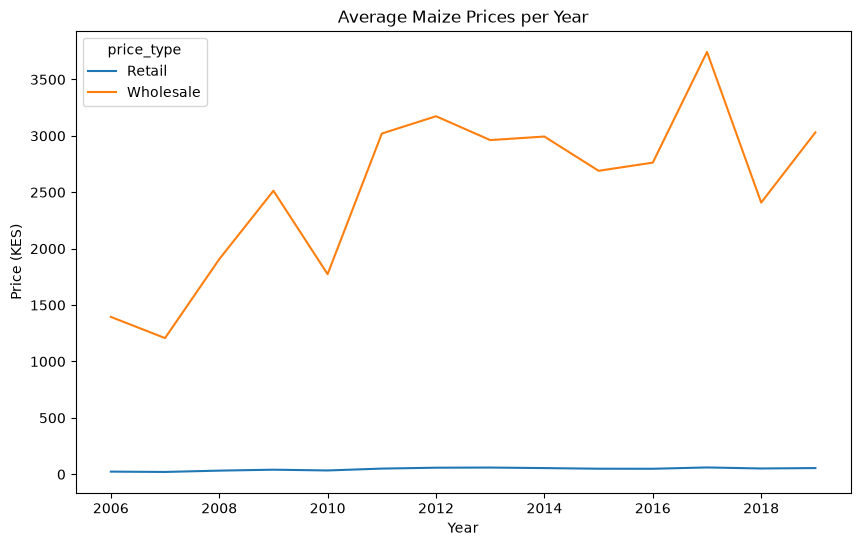

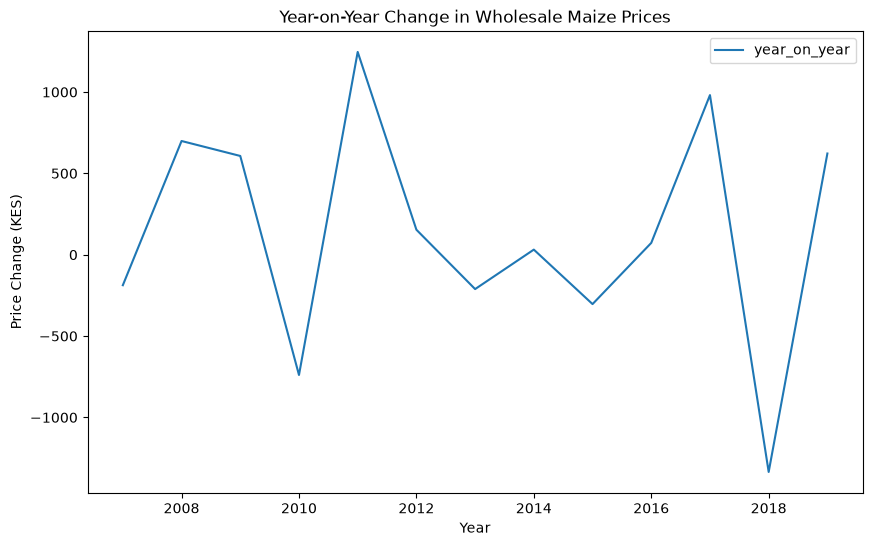

In [7]:
""" Maize prices over the years
Calculate the average wholesale maize price per bag for each year and the year-on-year change. 
Plot the yearly average as a line chart with the price in KES on the y-axis.
- Which year had the highest average wholesale maize price? --> {2017}
- Which year saw the biggest rise, and which saw the biggest fall, compared with the year before? -- 
"""

# Compare wholesale and retail maize prices only
maize = df[df["commodity"] == "Maize"] 

avg_prices = maize.groupby(["year", "price_type"])["price_per_kg"].mean().reset_index()

yearly_avg = maize.groupby("year")["price_kes"].mean().reset_index() 


# Average maize prices by year and price type
avg_prices = (maize.groupby(["year", "price_type"])["price_kes"].mean().reset_index())

avg_prices_pivot = avg_prices.pivot(index="year", columns="price_type", values="price_kes")

# Yearly wholesale average and year-on-year change
yearly_avg = (maize[maize["price_type"] == "Wholesale"].groupby("year")["price_kes"].mean().reset_index())

yearly_avg["year_on_year"] = yearly_avg["price_kes"].diff()

# Plot yearly average prices
avg_prices_pivot.plot(
    title="Average Maize Prices per Year",
    ylabel="Price (KES)",
    xlabel="Year",
    figsize=(10, 6)
)

# Plot year on year change in wholesale prices
yearly_avg.plot(
    x="year",
    y="year_on_year",
    title="Year-on-Year Change in Wholesale Maize Prices",
    ylabel="Price Change (KES)",
    xlabel="Year",
    figsize=(10, 6)
)

print(f"Highest wholesale price year: {yearly_avg.loc[yearly_avg['price_kes'].idxmax(), 'year']}")
print(f"Biggest rise: {yearly_avg.loc[yearly_avg['year_on_year'].idxmax(), 'year']}")
print(f"Biggest fall: {yearly_avg.loc[yearly_avg['year_on_year'].idxmin(), 'year']}")

yearly_avg


Cheapest month: 1 (KES 2329.51)
Dearest month: 6 (KES 2839.47)
June was higher than January in 73.3% of market-years.
Median June-minus-January gain: KES 356.00
This calculation excludes storage costs, transport, handling, financing, spoilage, pests, theft, quality loss, and price uncertainty.


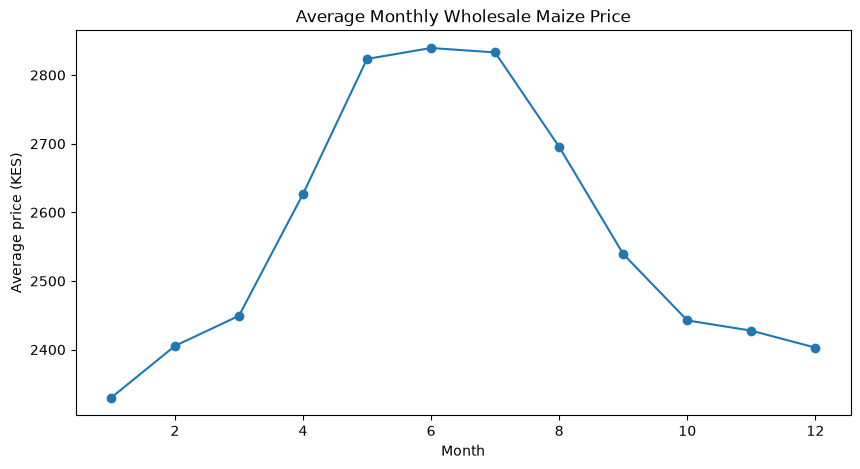

In [8]:
"""Sell at harvest or hold?
Average wholesale maize prices by month to find the seasonal pattern. Then compare each market's January and June price, 
year by year, to see how often storing maize for five months paid off.
- In which month is wholesale maize cheapest on average, and in which is it dearest?
- In what share of market-years was the June price higher than the January price, and what was the median gain?
- What costs and risks of storing maize does this calculation leave out?
"""

# Filter to wholesale maize prices
wholesale_maize = df[(df["commodity"] == "Maize") & (df["price_type"] == "Wholesale")].copy()

# Average wholesale price by month
monthly_prices = (wholesale_maize.groupby("month")["price_kes"].mean().reindex(range(1, 13)))

cheapest_month = monthly_prices.idxmin()
dearest_month = monthly_prices.idxmax()

print(f"Cheapest month: {cheapest_month} "f"(KES {monthly_prices.min():.2f})")
print(f"Dearest month: {dearest_month} "f"(KES {monthly_prices.max():.2f})")

monthly_prices.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Average Monthly Wholesale Maize Price",
    xlabel="Month",
    ylabel="Average price (KES)"
)

# Compare January and June prices for each market-year
market_year_prices = (wholesale_maize[wholesale_maize["month"].isin([1, 6])]
    .groupby(["market", "year", "month"])["price_kes"]
    .mean()
    .unstack("month")
    .rename(columns={1: "January", 6: "June"})
    .dropna(subset=["January", "June"])
)

market_year_prices["gain"] = (market_year_prices["June"] - market_year_prices["January"])

# Calculate the share of market-years where June was higher than January and the median gain
share_higher = (market_year_prices["gain"] > 0).mean() * 100
median_gain = market_year_prices["gain"].median()

print(f"June was higher than January in {share_higher:.1f}% " "of market-years.")
print(f"Median June-minus-January gain: KES {median_gain:.2f}")


print("This calculation excludes storage costs, transport, handling, financing, spoilage, pests, theft, quality loss, and price uncertainty.")




In [9]:
""" Where households pay most, and your advice
Compare average retail maize prices across the nine county markets for 2015 to 2019, then rank the markets within each year. 
Write your note for Pamoja with advice backed by your numbers.

- Which retail market was the most expensive on average from 2015 to 2019, and which was the cheapest?
- Which markets ranked in the top three every single year?
- What would you tell a farmer group about when to sell, and which markets should county officers watch?
"""



' Where households pay most, and your advice\nCompare average retail maize prices across the nine county markets for 2015 to 2019, then rank the markets within each year. \nWrite your note for Pamoja with advice backed by your numbers.\n\n- Which retail market was the most expensive on average from 2015 to 2019, and which was the cheapest?\n- Which markets ranked in the top three every single year?\n- What would you tell a farmer group about when to sell, and which markets should county officers watch?\n'